# Statistical Trend Analysis and Autoregressive Baseline: GRACE/GRACE-FO Water Storage

This notebook

1. loads the JPL GRACE/GRACE-FO mascon terrestrial water storage (TWS) data and puts it on a regular monthly grid;
2. tests every land cell for a monotonic trend with the **Mann–Kendall test** (Hamed–Rao correction for autocorrelation), estimates the trend size with **Sen's slope**, and controls the false discovery rate (**Benjamini–Hochberg**) across cells;
3. repeats the trend analysis on the **full 2002–2025 record** as a robustness check;
4. fits a per-cell **autoregressive (AR) baseline** on 2019–2023 and scores one-month-ahead predictions on 2024–2025;
5. saves figures, tables and a NetCDF file of the results to `outputs/`.

**To run in Google Colab:** Runtime → Run all. You will be asked to allow Google Drive access (results and the downloaded data are kept in `My Drive/DATA 255 Group Project`) and for your NASA Earthdata username and password. A free account is at urs.earthdata.nasa.gov.

In [25]:
# Installs the packages Colab does not include by default
%pip install -q earthaccess netCDF4

In [26]:
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

## Colab setup
Saves everything to Google Drive so results and the downloaded data survive the session. Set `USE_DRIVE = False` to work in the temporary Colab folder instead.

In [27]:
IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True
DRIVE_FOLDER = "/content/drive/MyDrive/DATA 255 Group Project"

if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(DRIVE_FOLDER, exist_ok=True)
    os.chdir(DRIVE_FOLDER)
print("Working folder:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working folder: /content/drive/MyDrive/DATA 255 Group Project


## Settings

In [28]:
DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"

# Leave empty to download from NASA Earthdata, or point to files you already have
MASCON_FILE = ""
LAND_MASK_FILE = ""
SHORT_NAME = "TELLUS_GRAC-GRFO_MASCON_CRI_GRID_RL06.3_V4"

RESOLUTION = 0.5              # degrees: 0.5 = GRACE grid as distributed; 1.0 = coarser, faster
LAT_MIN, LAT_MAX = -60, 60

WINDOW = ("2019-01", "2025-12")   # analysis window (GRACE-FO)
FULL = ("2002-04", "2025-12")     # full GRACE + GRACE-FO record
TRAIN = ("2019-01", "2023-12")    # AR baseline training period
TEST = ("2024-01", "2025-12")     # AR baseline test period

ALPHA = 0.05            # significance level and FDR level
HR_LAGS = 3             # autocorrelation lags used by the Hamed–Rao correction (Hamed & Rao, 1998)
MIN_MONTHS = 24         # minimum valid months for a trend test
MAX_AR_ORDER = 3
MIN_TEST_MONTHS = 12    # minimum scored months per cell for the AR metrics

# Case-study regions: (lat_min, lat_max, lon_min, lon_max), longitudes in -180..180
REGIONS = {
    "Northern India": (24, 32, 72, 84),
    "Central Valley, California": (35, 40, -122.5, -118.5),
    "Middle East (Tigris–Euphrates)": (30, 38, 38, 48),
    "Amazon": (-10, 0, -70, -55),
    "East Africa (Lake Victoria)": (-4, 2, 29, 36),
    "Northern Great Plains": (42, 50, -105, -95),
}

for d in (DATA_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

In [29]:
# Chart styling
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID, AXIS = "#fcfcfb", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})

# Diverging: red = water loss, gray = no change, blue = water gain
DIVERGING = LinearSegmentedColormap.from_list(
    "tws_div", ["#9e2427", RED, "#ee8c89", "#f6c4c2", "#f0efec",
                "#b7d3f6", "#6da7ec", BLUE, "#104281"])
DIVERGING.set_bad(SURFACE)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

## 1. Download the mascon data

In [30]:
# Reuse files from an earlier run (e.g., saved in Drive) before downloading again
if not MASCON_FILE:
    MASCON_FILE = next((str(f) for f in sorted(DATA_DIR.glob("*MSCN*.nc")) if "SCALE" not in f.name.upper()), "")
    LAND_MASK_FILE = LAND_MASK_FILE or next((str(f) for f in sorted(DATA_DIR.glob("*LAND_MASK*.nc"))), "")

if not MASCON_FILE:
    import earthaccess

    earthaccess.login()  # prompts for your Earthdata username and password
    results = earthaccess.search_data(short_name=SHORT_NAME)
    files = [Path(f) for f in earthaccess.download(results, local_path=str(DATA_DIR))]
    for f in files:
        name = f.name.upper()
        if "LAND_MASK" in name and not LAND_MASK_FILE:
            LAND_MASK_FILE = str(f)
        elif name.endswith(".NC") and "MSCN" in name and "SCALE" not in name:
            MASCON_FILE = str(f)

print("Mascon file:   ", MASCON_FILE)
print("Land mask file:", LAND_MASK_FILE or "(none; using the land_mask stored in the mascon file)")

Mascon file:    data/GRCTellus.JPL.200204_202607.GLO.RL06.3M.MSCNv04CRI.nc
Land mask file: (none; using the land_mask stored in the mascon file)


## 2. Load and tidy

* Converts longitudes to −180…180 and uses the land mask stored in the mascon file.
* Assigns each solution to a calendar month and puts the data on a regular monthly index; missing months (including the 2017–18 gap between the missions) become NaN.
* Keeps the GRACE 0.5° grid (cell centers at .25/.75), or averages to 1° if `RESOLUTION = 1.0`, and keeps land cells between `LAT_MIN` and `LAT_MAX`.

In [31]:
def to_pm180(da):
    return da.assign_coords(lon=((da.lon + 180) % 360) - 180).sortby("lon")


def load_land_mask(path, like):
    if path:
        ds = xr.open_dataset(path)
        mask = to_pm180(ds[list(ds.data_vars)[0]].squeeze(drop=True))
        return mask.reindex_like(like, method="nearest") > 0.5
    try:
        import regionmask
        land = regionmask.defined_regions.natural_earth_v5_0_0.land_110
        return land.mask(like.lon, like.lat).notnull()
    except Exception:
        print("WARNING: no land mask available; using all cells.")
        return xr.ones_like(like.isel(time=0), dtype=bool).drop_vars("time")


def assign_months(times):
    # Calendar month of each solution. A few solutions span two months, so their midpoint
    # lands in the neighboring month; move them into the empty month next to them.
    months = list(pd.DatetimeIndex(times).to_period("M"))
    for k in range(1, len(months)):
        if months[k] != months[k - 1]:
            continue
        prev_empty = k < 2 or months[k - 2] < months[k - 1] - 1
        next_empty = k + 1 >= len(months) or months[k + 1] > months[k] + 1
        if prev_empty:
            months[k - 1] -= 1
        elif next_empty:
            months[k] += 1
    return pd.PeriodIndex(months).to_timestamp()


def load_mascon(path, land_path=""):
    ds = xr.open_dataset(path)
    tws = to_pm180(ds["lwe_thickness"].astype("float32"))  # cm equivalent water height

    # One value per calendar month, on a complete monthly index
    months = assign_months(tws.time.values)
    tws = tws.assign_coords(time=months).groupby("time").mean()
    full_index = pd.date_range(months.min(), months.max(), freq="MS")
    tws = tws.reindex(time=full_index)

    if not land_path and "land_mask" in ds:
        land = to_pm180(ds["land_mask"]) > 0.5  # land mask stored in the mascon file
    else:
        land = load_land_mask(land_path, tws)
    if RESOLUTION == 1.0:
        tws = tws.coarsen(lat=2, lon=2, boundary="trim").mean()
        land = land.astype(float).coarsen(lat=2, lon=2, boundary="trim").mean() >= 0.5

    lat_slice = slice(LAT_MIN, LAT_MAX)
    tws, land = tws.sel(lat=lat_slice), land.sel(lat=lat_slice)
    return tws.where(land), land


tws, land = load_mascon(MASCON_FILE, LAND_MASK_FILE)
weights = np.cos(np.deg2rad(tws.lat)).broadcast_like(land).where(land)  # area weights
print(f"Grid: {tws.sizes['lat']} x {tws.sizes['lon']} at {RESOLUTION}°, "
      f"{pd.Timestamp(tws.time.values[0]):%Y-%m} to {pd.Timestamp(tws.time.values[-1]):%Y-%m}")
print(f"Land cells: {int(land.sum())} of {land.size}")

Grid: 240 x 720 at 0.5°, 2002-04 to 2026-07
Land cells: 46325 of 172800


In [32]:
def missing_months(da, period):
    sub = da.sel(time=slice(*period))
    present = sub.notnull().any(["lat", "lon"])
    return sub.time.values[~present.values]

for label, period in [("Window", WINDOW), ("Full record", FULL)]:
    miss = missing_months(tws, period)
    n_total = len(pd.date_range(*period, freq="MS"))
    print(f"{label} {period[0]}–{period[1]}: {n_total - len(miss)}/{n_total} months present")
    print("  missing:", ", ".join(pd.DatetimeIndex(miss).strftime("%Y-%m")) or "none")

Window 2019-01–2025-12: 84/84 months present
  missing: none
Full record 2002-04–2025-12: 252/285 months present
  missing: 2002-06, 2002-07, 2003-06, 2011-01, 2011-06, 2012-05, 2012-10, 2013-03, 2013-08, 2013-09, 2014-02, 2014-07, 2014-12, 2015-06, 2015-10, 2015-11, 2016-04, 2016-09, 2016-10, 2017-02, 2017-07, 2017-08, 2017-09, 2017-10, 2017-11, 2017-12, 2018-01, 2018-02, 2018-03, 2018-04, 2018-05, 2018-08, 2018-09


## 3. Trend tests

For each land cell, on the deseasonalized series (each calendar month's mean removed):

* **Mann–Kendall** S statistic and Kendall's τ, with the tie-corrected variance. The *naive* p-value assumes independent months.
* **Hamed–Rao correction:** inflates the variance of S using the significant autocorrelations (first `HR_LAGS` lags, as Hamed & Rao recommend) of the ranks of the detrended series. Monthly TWS is strongly autocorrelated, so the naive test overstates significance. The correction is never allowed to shrink the variance.
* **Sen's slope** (Theil–Sen) against real time in decimal years, giving cm/year with a 95% confidence interval.
* **Benjamini–Hochberg FDR** across all land cells, because testing thousands of cells at α = 0.05 would otherwise produce many false positives.

Missing months are dropped, so the Hamed–Rao autocorrelation treats the remaining months as consecutive.

In [33]:
_PAIRS = {}

def _pairs(n):
    if n not in _PAIRS:
        _PAIRS[n] = np.triu_indices(n, 1)
    return _PAIRS[n]


def _acf(x, nlags):
    x = x - x.mean()
    denom = np.dot(x, x)
    return np.array([np.dot(x[: len(x) - k], x[k:]) / denom for k in range(1, nlags + 1)])


def mann_kendall(x, alpha=ALPHA):
    # Mann-Kendall test on a gap-free series, with naive and Hamed-Rao p-values
    n = len(x)
    i, j = _pairs(n)
    s = np.sign(x[j] - x[i]).sum()
    _, counts = np.unique(x, return_counts=True)
    var_s = (n * (n - 1) * (2 * n + 5) - np.sum(counts * (counts - 1) * (2 * counts + 5))) / 18
    tau = s / (n * (n - 1) / 2)

    def p_value(var):
        z = 0.0 if s == 0 else (s - np.sign(s)) / np.sqrt(var)
        return 2 * stats.norm.sf(abs(z))

    # Hamed & Rao (1998): autocorrelation of ranks of the detrended series
    slope_idx = np.median((x[j] - x[i]) / (j - i))
    ranks = stats.rankdata(x - slope_idx * np.arange(n))
    lags = min(HR_LAGS, n - 1)
    rho = _acf(ranks, lags)
    k = np.arange(1, lags + 1)
    keep = np.abs(rho) > stats.norm.ppf(1 - alpha / 2) / np.sqrt(n)
    factor = 1 + 2 / (n * (n - 1) * (n - 2)) * np.sum(((n - k) * (n - k - 1) * (n - k - 2) * rho)[keep])
    factor = max(factor, 1.0)
    return tau, p_value(var_s), p_value(var_s * factor)


def bh_fdr(p):
    # Benjamini-Hochberg adjusted p-values (q-values); NaNs are ignored
    q = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    pv = p[ok]
    order = np.argsort(pv)
    ranked = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty_like(pv)
    out[order] = np.clip(ranked, 0, 1)
    q[ok] = out
    return q


def decimal_years(times):
    t = pd.DatetimeIndex(times)
    return t.year + (t.month - 0.5) / 12


def deseasonalize(da, ref_period):
    clim = da.sel(time=slice(*ref_period)).groupby("time.month").mean("time")
    return (da.groupby("time.month") - clim).drop_vars("month"), clim

### Check: false positive rates on simulated data
Series with **no trend** but AR(1) autocorrelation φ, at the two record lengths. A well-calibrated test rejects about 5% of the time.

In [34]:
rng = np.random.default_rng(0)


def ar1_series(n, phi):
    x = np.zeros(n)
    e = rng.normal(size=n)
    for t in range(n):
        x[t] = (phi * x[t - 1] if t else 0) + e[t]
    return x


check_rows = []
for label, period in [("2019–2025", WINDOW), ("2002–2025", FULL)]:
    n = len(pd.date_range(*period, freq="MS"))
    for phi in (0.0, 0.5, 0.7, 0.9):
        p = np.array([mann_kendall(ar1_series(n, phi))[1:] for _ in range(500)])
        check_rows.append({"Record": label, "Months": n, "phi": phi,
                           "Naive MK (%)": 100 * np.mean(p[:, 0] < ALPHA),
                           "Hamed–Rao (%)": 100 * np.mean(p[:, 1] < ALPHA)})
fp_table = pd.DataFrame(check_rows).round(1)
fp_table.to_csv(OUT_DIR / "false_positive_check.csv", index=False)
fp_table

,Record,Months,phi,Naive MK (%),Hamed–Rao (%)
0,2019–2025,84,0.0,6.8,6.8
1,2019–2025,84,0.5,25.8,10.6
2,2019–2025,84,0.7,42.2,19.0
3,2019–2025,84,0.9,59.2,26.2
4,2002–2025,285,0.0,4.0,3.6
5,2002–2025,285,0.5,24.0,6.4
6,2002–2025,285,0.7,40.0,11.0
7,2002–2025,285,0.9,60.4,25.4


In [35]:
def trend_analysis(da, period):
    anom, _ = deseasonalize(da.sel(time=slice(*period)), period)
    t = decimal_years(anom.time.values)
    data = anom.transpose("lat", "lon", "time").values
    names = ["tau", "p_naive", "p_hr", "slope", "slope_lo", "slope_hi", "n"]
    res = {k: np.full(data.shape[:2], np.nan) for k in names}

    cells = np.argwhere(land.values)
    for c, (a, b) in enumerate(cells):
        y = data[a, b]
        ok = ~np.isnan(y)
        if ok.sum() < MIN_MONTHS:
            continue
        x, tt = y[ok].astype(float), t[ok]
        tau, p_naive, p_hr = mann_kendall(x)
        slope, _, lo, hi = stats.theilslopes(x, tt, alpha=0.95)
        for k, v in zip(names, (tau, p_naive, p_hr, slope, lo, hi, ok.sum())):
            res[k][a, b] = v
        if (c + 1) % 10000 == 0:
            print(f"  {c + 1}/{len(cells)} cells")

    out = xr.Dataset({k: (("lat", "lon"), v) for k, v in res.items()},
                     coords={"lat": anom.lat, "lon": anom.lon})
    out["q_hr"] = (("lat", "lon"), bh_fdr(out["p_hr"].values))
    out["sig"] = (np.sign(out["slope"]) * (out["q_hr"] < ALPHA)).fillna(0).astype("int8")  # 0 also for ocean
    return out, anom


print("Window:")
trend_win, anom_win = trend_analysis(tws, WINDOW)
print("Full record:")
trend_full, anom_full = trend_analysis(tws, FULL)

Window:
  10000/46325 cells
  20000/46325 cells
  30000/46325 cells
  40000/46325 cells
Full record:
  10000/46325 cells
  20000/46325 cells
  30000/46325 cells
  40000/46325 cells


### How much land shows a significant trend?
Area-weighted share of land cells, with each correction added in turn.

In [36]:
def area_share(mask):
    return float(weights.where(mask).sum() / weights.sum() * 100)


rows = []
for label, tr in [("2019–2025", trend_win), ("2002–2025", trend_full)]:
    for method, sig in [("Naive MK (p < 0.05)", tr.p_naive < ALPHA),
                        ("Hamed–Rao (p < 0.05)", tr.p_hr < ALPHA),
                        ("Hamed–Rao + FDR (q < 0.05)", tr.q_hr < ALPHA)]:
        rows.append({"Record": label, "Method": method,
                     "Rising (% land)": area_share(sig & (tr.slope > 0)),
                     "Declining (% land)": area_share(sig & (tr.slope < 0))})
sig_table = pd.DataFrame(rows).round(1)
sig_table.to_csv(OUT_DIR / "significance_summary.csv", index=False)
sig_table

,Record,Method,Rising (% land),Declining (% land)
0,2019–2025,Naive MK (p < 0.05),37.2,40.6
1,2019–2025,Hamed–Rao (p < 0.05),26.4,32.5
2,2019–2025,Hamed–Rao + FDR (q < 0.05),22.1,30.5
3,2002–2025,Naive MK (p < 0.05),41.6,46.4
4,2002–2025,Hamed–Rao (p < 0.05),35.3,39.3
5,2002–2025,Hamed–Rao + FDR (q < 0.05),34.7,38.7


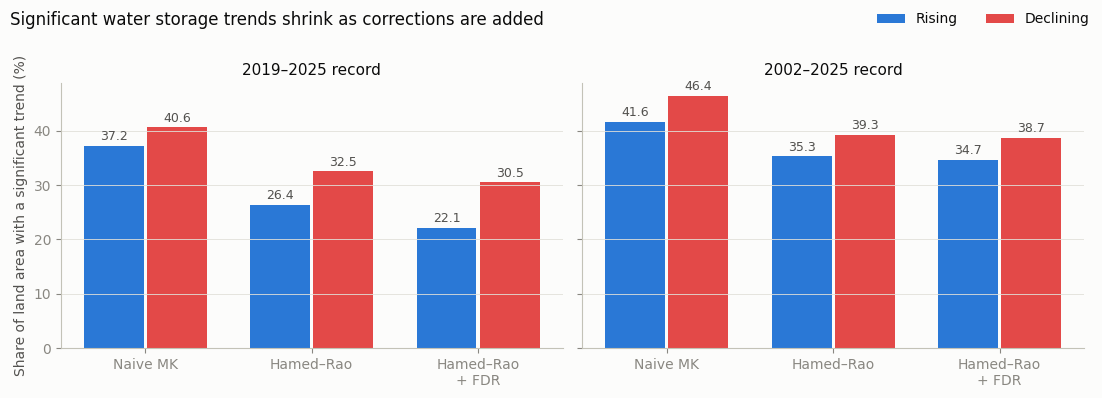

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
methods = ["Naive MK", "Hamed–Rao", "Hamed–Rao\n+ FDR"]
x = np.arange(len(methods))
w = 0.36
for ax, label in zip(axes, ["2019–2025", "2002–2025"]):
    sub = sig_table[sig_table.Record == label]
    for offset, col, color, name in [(-w / 2 - 0.01, "Rising (% land)", BLUE, "Rising"),
                                     (w / 2 + 0.01, "Declining (% land)", RED, "Declining")]:
        bars = ax.bar(x + offset, sub[col], width=w, color=color, label=name)
        ax.bar_label(bars, fmt="%.1f", padding=2, color=INK_2, fontsize=9)
    ax.set_xticks(x, methods)
    ax.set_title(f"{label} record")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of land area with a significant trend (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.suptitle("Significant water storage trends shrink as corrections are added", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.97))
savefig(fig, "significance_by_method")

### Trend maps
Sen's slope; dots (on a 1.5° pattern) mark areas significant after the Hamed–Rao and FDR corrections. Both maps use the same color scale.

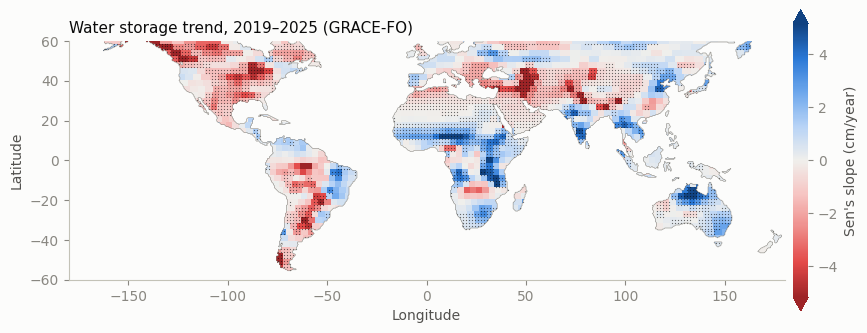

In [38]:
vmax = float(np.nanpercentile(np.abs(np.concatenate(
    [trend_win.slope.values.ravel(), trend_full.slope.values.ravel()])), 98))


def plot_slope_map(tr, title, name, label="Sen's slope (cm/year)", data=None, vlim=None):
    data = tr.slope if data is None else data
    vlim = vmax if vlim is None else vlim
    fig, ax = plt.subplots(figsize=(11, 4.6))
    mesh = ax.pcolormesh(data.lon, data.lat, data, cmap=DIVERGING, vmin=-vlim, vmax=vlim, shading="auto")
    ax.contour(land.lon, land.lat, land.astype(float), levels=[0.5], colors=MUTED, linewidths=0.4)
    if tr is not None:
        # Dots on a 1.5° pattern so they don't hide the colors (mascons are 3° anyway)
        step = max(1, int(round(1.5 / RESOLUTION)))
        sig = (tr.sig != 0).values[::step, ::step]
        lon2, lat2 = np.meshgrid(tr.lon.values[::step], tr.lat.values[::step])
        ax.scatter(lon2[sig], lat2[sig], s=0.8, c=INK, linewidths=0, alpha=0.6)
    cb = fig.colorbar(mesh, ax=ax, shrink=0.85, pad=0.01, extend="both")
    cb.set_label(label, color=INK_2)
    cb.outline.set_visible(False)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal")
    ax.grid(False)
    savefig(fig, name)
    return fig


plot_slope_map(trend_win, "Water storage trend, 2019–2025 (GRACE-FO)", "trend_map_2019_2025");

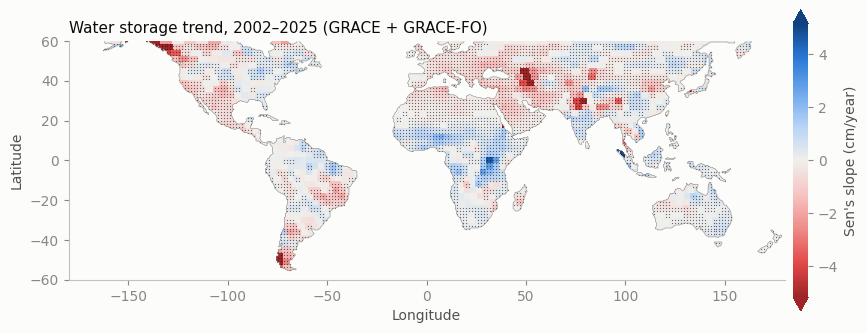

In [39]:
plot_slope_map(trend_full, "Water storage trend, 2002–2025 (GRACE + GRACE-FO)", "trend_map_2002_2025");

### Short window vs full record
Each dot is a land cell. Cells off the diagonal quadrants have opposite trend signs in the two records, which is where a 7-year window disagrees with the long-term trend.

Cells with opposite trend signs: 31.3% of land area
  among cells significant in the full record: 24.2%
Correlation of the two slope maps: r = 0.66
Axis limit ±9.01 cm/year; 275 extreme cells (e.g., glaciers) fall outside the plot


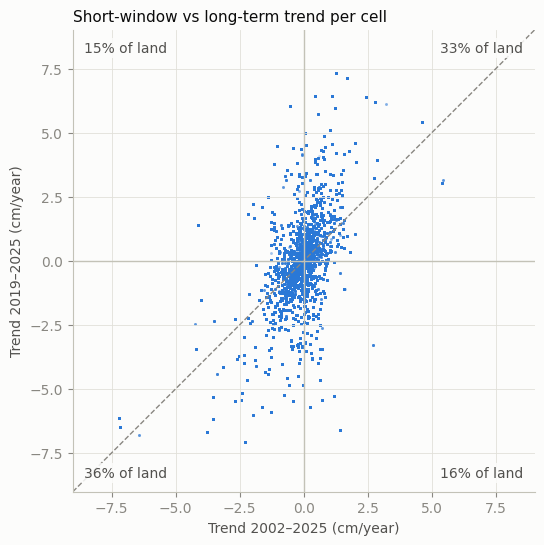

In [40]:
both = (trend_win.slope.notnull() & trend_full.slope.notnull()).values
s_win, s_full = trend_win.slope.values[both], trend_full.slope.values[both]
w_cells = weights.values[both]
sig_full = (trend_full.sig != 0).values[both]


def pct(mask, base=None):
    base = np.ones_like(mask, bool) if base is None else base
    return 100 * w_cells[mask & base].sum() / w_cells[base].sum()


flip = np.sign(s_win) != np.sign(s_full)
print(f"Cells with opposite trend signs: {pct(flip):.1f}% of land area")
print(f"  among cells significant in the full record: {pct(flip, sig_full):.1f}%")
print(f"Correlation of the two slope maps: r = {np.corrcoef(s_win, s_full)[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(s_full, s_win, s=4, color=BLUE, alpha=0.25, linewidths=0)
lim = 1.1 * float(np.nanpercentile(np.abs(np.r_[s_win, s_full]), 99.5))
n_out = int(((np.abs(s_win) > lim) | (np.abs(s_full) > lim)).sum())
print(f"Axis limit ±{lim:.2f} cm/year; {n_out} extreme cells (e.g., glaciers) fall outside the plot")
ax.plot([-lim, lim], [-lim, lim], color=MUTED, linewidth=1, linestyle="--")
ax.axhline(0, color=AXIS, linewidth=1)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
for sx, sy, ha, va in [(1, 1, "right", "top"), (-1, 1, "left", "top"),
                       (-1, -1, "left", "bottom"), (1, -1, "right", "bottom")]:
    q = (np.sign(s_full) == sx) & (np.sign(s_win) == sy)
    ax.text(sx * lim * 0.95, sy * lim * 0.95, f"{pct(q):.0f}% of land", ha=ha, va=va, color=INK_2,
            bbox=dict(facecolor=SURFACE, edgecolor="none", alpha=0.85, pad=2))
ax.set_xlabel("Trend 2002–2025 (cm/year)")
ax.set_ylabel("Trend 2019–2025 (cm/year)")
ax.set_title("Short-window vs long-term trend per cell", loc="left")
ax.set_aspect("equal")
savefig(fig, "trend_window_vs_full")

### Case-study regions
Area-weighted regional mean of the deseasonalized series, with Sen's slope fitted to each record.

In [41]:
def region_mean(da, box):
    la0, la1, lo0, lo1 = box
    sub = da.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
    w = weights.sel(lat=slice(la0, la1), lon=slice(lo0, lo1))
    return (sub * w).sum(["lat", "lon"], min_count=1) / w.where(sub.notnull()).sum(["lat", "lon"])


def series_trend(series):
    ok = series.notnull().values
    x, t = series.values[ok], decimal_years(series.time.values[ok])
    tau, _, p_hr = mann_kendall(x.astype(float))
    slope, intercept, lo, hi = stats.theilslopes(x, t, alpha=0.95)
    return dict(n=int(ok.sum()), tau=tau, p_hr=p_hr, slope=slope, lo=lo, hi=hi, intercept=intercept)


region_rows, region_series = [], {}
for name, box in REGIONS.items():
    s = region_mean(anom_full, box)
    region_series[name] = s
    for label, period in [("2019–2025", WINDOW), ("2002–2025", FULL)]:
        r = series_trend(s.sel(time=slice(*period)))
        region_rows.append({"Region": name, "Record": label, "Months": r["n"],
                            "Sen's slope (cm/yr)": r["slope"],
                            "95% CI": f"[{r['lo']:.2f}, {r['hi']:.2f}]",
                            "Kendall tau": r["tau"], "p (Hamed–Rao)": r["p_hr"]})
region_table = pd.DataFrame(region_rows).round(3)
region_table.to_csv(OUT_DIR / "region_trends.csv", index=False)
region_table

,Region,Record,Months,Sen's slope (cm/yr),95% CI,Kendall tau,p (Hamed–Rao)
0,Northern India,2019–2025,84,-0.229,"[-0.68, 0.26]",-0.076,0.604
1,Northern India,2002–2025,252,-1.950,"[-2.04, -1.85]",-0.733,0.000
2,"Central Valley, California",2019–2025,84,-0.436,"[-1.50, 0.74]",-0.057,0.740
3,"Central Valley, California",2002–2025,252,-1.200,"[-1.38, -1.03]",-0.519,0.000
4,Middle East (Tigris–Euphrates),2019–2025,84,-2.692,"[-3.07, -2.33]",-0.687,0.000
5,Middle East (Tigris–Euphrates),2002–2025,252,-0.858,"[-0.95, -0.77]",-0.627,0.000
6,Amazon,2019–2025,84,-2.034,"[-3.33, -0.95]",-0.291,0.094
7,Amazon,2002–2025,252,0.347,"[0.17, 0.50]",0.157,0.104
8,East Africa (Lake Victoria),2019–2025,84,3.543,"[2.03, 5.20]",0.377,0.031
9,East Africa (Lake Victoria),2002–2025,252,2.747,"[2.53, 2.96]",0.654,0.000


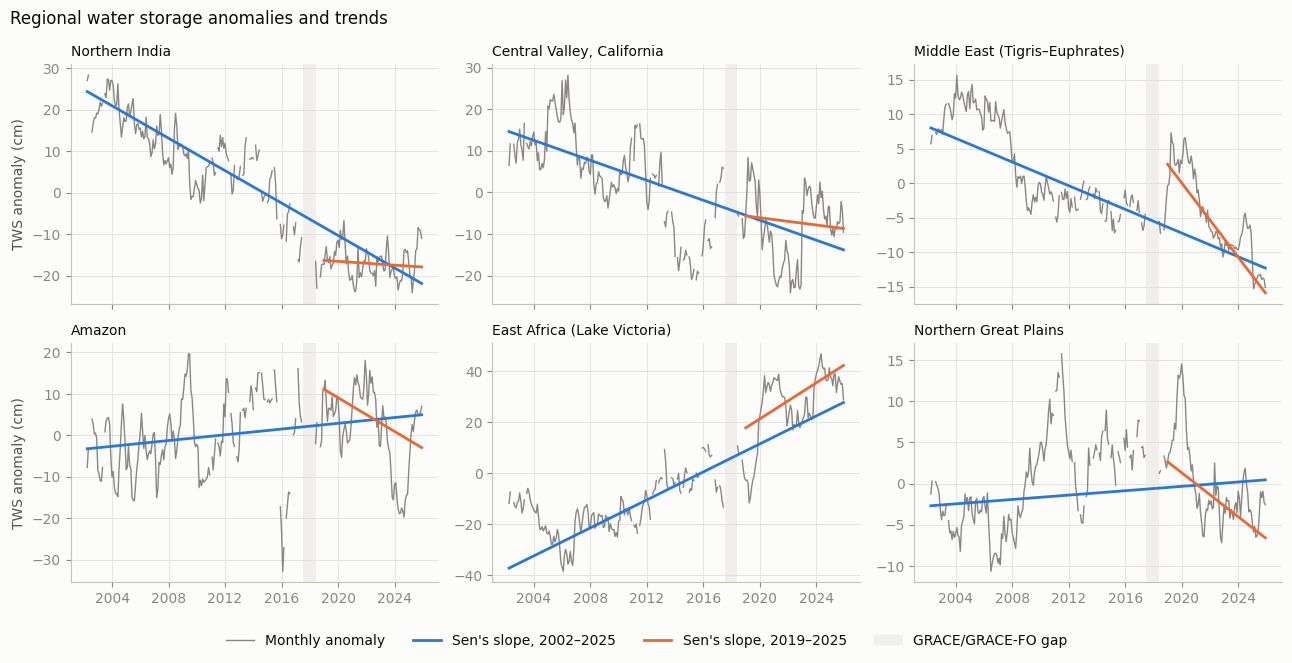

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
for ax, (name, s) in zip(axes.flat, region_series.items()):
    ax.axvspan(pd.Timestamp("2017-07-01"), pd.Timestamp("2018-05-31"), color="#f0efec", lw=0)
    ax.plot(s.time, s, color=MUTED, linewidth=1)
    for period, color in [(FULL, BLUE), (WINDOW, ORANGE)]:
        sub = s.sel(time=slice(*period))
        r = series_trend(sub)
        t = decimal_years(sub.time.values)
        ax.plot(sub.time, r["intercept"] + r["slope"] * t, color=color)
    ax.set_title(name, loc="left", fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel("TWS anomaly (cm)")
handles = [plt.Line2D([], [], color=MUTED, linewidth=1, label="Monthly anomaly"),
           plt.Line2D([], [], color=BLUE, label="Sen's slope, 2002–2025"),
           plt.Line2D([], [], color=ORANGE, label="Sen's slope, 2019–2025"),
           plt.Rectangle((0, 0), 1, 1, color="#f0efec", label="GRACE/GRACE-FO gap")]
fig.legend(handles=handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Regional water storage anomalies and trends", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))
savefig(fig, "region_trends")

## 4. Autoregressive baseline

* Anomalies are taken relative to the **training-period** monthly means, so no test information is used.
* For each land cell, AR(p) models with an intercept are fitted for p = 1…`MAX_AR_ORDER` by least squares on 2019–2023, and the order with the lowest AIC is kept.
* Each test month (2024–2025) is predicted **one month ahead** from the observed previous p months; a month is skipped if any of those inputs is missing. The seasonal mean is then added back.
* For reference, the same months are also scored for **persistence** (last month's value) and **climatology** (the training-period mean for that calendar month).
* Metrics per cell: MAE, RMSE, correlation, and anomaly correlation (correlation after removing the seasonal cycle). Cells are averaged with area weights.
* The skill map shows 1 − RMSE(AR) / RMSE(persistence): positive where AR is better, 1 for a perfect AR prediction.

In [43]:
sub = tws.sel(time=slice(TRAIN[0], TEST[1]))
anom_ar, clim_ar = deseasonalize(sub, TRAIN)
times = pd.DatetimeIndex(sub.time.values)
is_train = (times >= TRAIN[0]) & (times <= pd.Timestamp(TRAIN[1]) + pd.offsets.MonthEnd(0))
is_test = (times >= TEST[0]) & (times <= pd.Timestamp(TEST[1]) + pd.offsets.MonthEnd(0))
seasonal = clim_ar.sel(month=times.month).transpose("month", "lat", "lon").values  # (time, lat, lon)

A = anom_ar.transpose("time", "lat", "lon").values
Y = sub.transpose("time", "lat", "lon").values
P = MAX_AR_ORDER
test_idx = np.where(is_test)[0]

ar_pred = np.full((len(test_idx),) + A.shape[1:], np.nan)
ar_order = np.zeros(A.shape[1:], dtype="int8")


def lagged(a, p):
    return np.column_stack([np.r_[np.full(k, np.nan), a[:-k]] for k in range(1, p + 1)])


for a_i, b_i in np.argwhere(land.values):
    a = A[:, a_i, b_i]
    lags = lagged(a, P)
    rows = is_train & ~np.isnan(a) & ~np.isnan(lags).any(axis=1)  # same rows for every order
    if rows.sum() < 24:
        continue
    best = None
    for p in range(1, P + 1):
        X = np.column_stack([np.ones(rows.sum()), lags[rows, :p]])
        beta, *_ = np.linalg.lstsq(X, a[rows], rcond=None)
        rss = np.sum((a[rows] - X @ beta) ** 2)
        aic = rows.sum() * np.log(rss / rows.sum()) + 2 * (p + 1)
        if best is None or aic < best[0]:
            best = (aic, p, beta)
    _, p, beta = best
    ar_order[a_i, b_i] = p
    X_test = np.column_stack([np.ones(len(test_idx)), lags[test_idx, :p]])
    ar_pred[:, a_i, b_i] = X_test @ beta + seasonal[test_idx, a_i, b_i]  # NaN if a lag is missing

obs = Y[test_idx]
persist_pred = Y[test_idx - 1]
clim_pred = seasonal[test_idx]
print("AR order counts:", {p: int((ar_order == p).sum()) for p in range(1, P + 1)})

AR order counts: {1: 31954, 2: 7485, 3: 6886}


In [44]:
def cell_metrics(pred, obs, season):
    err = pred - obs
    mae = np.nanmean(np.abs(err), axis=0)
    rmse = np.sqrt(np.nanmean(err ** 2, axis=0))

    def corr(a, b):
        a = a - np.nanmean(a, axis=0)
        b = b - np.nanmean(b, axis=0)
        return np.nansum(a * b, axis=0) / np.sqrt(np.nansum(a ** 2, axis=0) * np.nansum(b ** 2, axis=0))

    return {"MAE (cm)": mae, "RMSE (cm)": rmse, "Correlation": corr(pred, obs),
            "Anomaly correlation": corr(pred - season, obs - season)}


# Score every model on the same months: where the observation and all three predictions exist
common = ~np.isnan(obs) & ~np.isnan(ar_pred) & ~np.isnan(persist_pred) & ~np.isnan(clim_pred)
enough = (common.sum(axis=0) >= MIN_TEST_MONTHS) & land.values
mask = lambda arr: np.where(common, arr, np.nan)
o, s = mask(obs), mask(clim_pred)

models = {"AR (this baseline)": mask(ar_pred), "Persistence (reference)": mask(persist_pred),
          "Climatology (reference)": mask(clim_pred)}
metrics = {m: cell_metrics(pred, o, s) for m, pred in models.items()}
w = np.where(enough, weights.values, np.nan)


def wmean(field, cells=enough):
    ok = cells & ~np.isnan(field)
    return np.nansum(field[ok] * w[ok]) / np.nansum(w[ok])


ar_table = pd.DataFrame({m: {k: wmean(v) for k, v in met.items()} for m, met in metrics.items()}).T
ar_table.loc["Climatology (reference)", "Anomaly correlation"] = np.nan  # undefined: zero anomaly
ar_table = ar_table.round(3)
print(f"Scored cells: {int(enough.sum())}, test months per cell (median): {int(np.median(common.sum(0)[enough]))}")
ar_table.to_csv(OUT_DIR / "ar_metrics_global.csv")
ar_table

Scored cells: 46325, test months per cell (median): 24


,MAE (cm),RMSE (cm),Correlation,Anomaly correlation
AR (this baseline),2.355,2.975,0.813,0.626
Persistence (reference),3.437,4.201,0.764,0.595
Climatology (reference),6.061,6.863,0.607,NaN


In [45]:
lat2, lon2 = np.meshgrid(tws.lat, tws.lon, indexing="ij")
region_metric_rows = []
for name, (la0, la1, lo0, lo1) in REGIONS.items():
    in_box = enough & (lat2 >= la0) & (lat2 <= la1) & (lon2 >= lo0) & (lon2 <= lo1)
    for m, met in metrics.items():
        row = {"Region": name, "Model": m}
        row.update({k: wmean(v, in_box) for k, v in met.items() if k != "Anomaly correlation"})
        region_metric_rows.append(row)
ar_region_table = pd.DataFrame(region_metric_rows).round(2)
ar_region_table.to_csv(OUT_DIR / "ar_metrics_regions.csv", index=False)
ar_region_table

,Region,Model,MAE (cm),RMSE (cm),Correlation
0,Northern India,AR (this baseline),4.19,5.47,0.90
1,Northern India,Persistence (reference),6.41,8.31,0.77
2,Northern India,Climatology (reference),9.52,11.07,0.82
3,"Central Valley, California",AR (this baseline),2.70,3.61,0.91
4,"Central Valley, California",Persistence (reference),4.26,5.01,0.83
5,"Central Valley, California",Climatology (reference),5.12,6.14,0.81
6,Middle East (Tigris–Euphrates),AR (this baseline),1.58,2.26,0.87
7,Middle East (Tigris–Euphrates),Persistence (reference),1.96,2.29,0.89
8,Middle East (Tigris–Euphrates),Climatology (reference),7.85,8.78,0.54
9,Amazon,AR (this baseline),5.96,7.37,0.97


AR beats persistence (lower RMSE) on 66.1% of scored land area


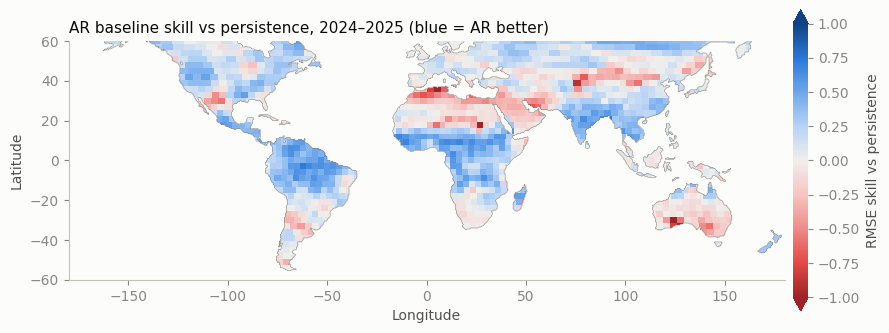

In [46]:
skill = 1 - metrics["AR (this baseline)"]["RMSE (cm)"] / metrics["Persistence (reference)"]["RMSE (cm)"]
skill = xr.DataArray(np.where(enough, skill, np.nan), coords={"lat": tws.lat, "lon": tws.lon})
print(f"AR beats persistence (lower RMSE) on {area_share(xr.DataArray(skill.values > 0, coords=skill.coords)):.1f}% of scored land area")
plot_slope_map(None, "AR baseline skill vs persistence, 2024–2025 (blue = AR better)", "ar_skill_vs_persistence",
               label="RMSE skill vs persistence", data=skill, vlim=1);

## 5. Save results

In [47]:
test_times = sub.time.values[test_idx]
out = xr.Dataset(
    {
        "tws_anom": anom_win.astype("float32"),
        "sen_slope": trend_win.slope, "sen_slope_lo": trend_win.slope_lo, "sen_slope_hi": trend_win.slope_hi,
        "mk_tau": trend_win.tau, "mk_p": trend_win.p_hr, "mk_q": trend_win.q_hr, "mk_sig": trend_win.sig,
        "sen_slope_full": trend_full.slope, "mk_p_full": trend_full.p_hr,
        "mk_q_full": trend_full.q_hr, "mk_sig_full": trend_full.sig,
        "ar_pred": (("test_time", "lat", "lon"), ar_pred.astype("float32")),
        "ar_order": (("lat", "lon"), ar_order),
    },
    coords={"test_time": test_times},
)
out["tws_anom"].attrs = {"units": "cm", "long_name": f"TWS anomaly, {WINDOW[0]} to {WINDOW[1]}, monthly means removed"}
for v in ["sen_slope", "sen_slope_lo", "sen_slope_hi", "sen_slope_full"]:
    out[v].attrs["units"] = "cm/year"
out["mk_sig"].attrs["long_name"] = "1 rising, -1 declining, 0 not significant (Hamed-Rao + BH FDR)"
out["ar_pred"].attrs = {"units": "cm", "long_name": "AR one-month-ahead TWS prediction"}
out.attrs = {"source": SHORT_NAME, "window": f"{WINDOW[0]} to {WINDOW[1]}", "full_record": f"{FULL[0]} to {FULL[1]}",
             "ar_train": f"{TRAIN[0]} to {TRAIN[1]}", "ar_test": f"{TEST[0]} to {TEST[1]}",
             "resolution_deg": RESOLUTION, "alpha": ALPHA}
out.to_netcdf(OUT_DIR / "trend_ar_outputs.nc")
print("Saved:", sorted(p.name for p in OUT_DIR.rglob("*") if p.is_file()))

Saved: ['ar_metrics_global.csv', 'ar_metrics_regions.csv', 'ar_skill_vs_persistence.png', 'false_positive_check.csv', 'region_trends.csv', 'region_trends.png', 'significance_by_method.png', 'significance_summary.csv', 'trend_ar_outputs.nc', 'trend_map_2002_2025.png', 'trend_map_2019_2025.png', 'trend_window_vs_full.png']


In [48]:
# Download all outputs as one zip (Colab)
if IN_COLAB:
    import shutil
    from google.colab import files
    shutil.make_archive("outputs", "zip", OUT_DIR)
    files.download("outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Caveats

* **Short window:** a 2019–2025 trend mixes long-term change with droughts and unusually wet years, so compare it with the 2002–2025 result before interpreting it.
* **Resolution:** the 0.5° grid samples 3° mascons (~300 km), so neighboring cells are strongly correlated and small regions are smoothed. Cell counts overstate the number of independent measurements.
* **Gaps:** missing months are dropped; the Hamed–Rao autocorrelation treats the remaining months as consecutive.
* **Residual autocorrelation:** the false positive check shows Hamed–Rao still rejects more than 5% of the time for strongly autocorrelated, short series, so treat borderline p-values with caution.
* **End of the GRACE mission:** solutions from late 2016 to mid-2017 are noisier (one accelerometer was switched off after August 2016), which can show up as spikes in regional series.
* **Ice and glaciers:** strong declines in glaciated areas (for example, Alaska and Patagonia) reflect ice loss, not groundwater.